# Food Recognition and Calorie Estimation

### Machine Learning Project

This project aims to recognize food items from images using a deep learning image classification model and estimate their calories using a nutritional reference dataset.

### Project Workflow

1. Load and explore the food image dataset
2. Preprocess food images
3. Perform data augmentation
4. Build the food recognition model
5. Train the model
6. Evaluate model performance
7. Predict food from a new image
8. Map the predicted food to its calorie information
9. Estimate calories based on serving quantity

In [2]:
!pip install tensorflow

  Using cached absl_py-2.5.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 2.6/384.1 MB 15.5 MB/s eta 0:00:25
   ---------------------------------------- 3.4/384.1 MB 9.0 MB/s eta 0:00:43
    --------------------------------------- 5.8/384.1 MB 9.2 MB/s eta 0:00:42
    --------------------------------------- 8.1/384.1 MB 9.7 MB/s eta 0:00:39

In [5]:
# ============================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
DATASET_PATH = r"C:\Users\Admin\Downloads\Indian Food Images"

# Nutrition dataset
NUTRITION_PATH = r"C:\Users\Admin\Downloads\Indian Food Images\Indian_Food_Nutrition_51_Matching_Image_Classes.csv"

print("Image dataset path:")
print(DATASET_PATH)

print("\nNutrition dataset path:")
print(NUTRITION_PATH)

# Check whether both paths exist
print("\nImage dataset exists:", os.path.exists(DATASET_PATH))
print("Nutrition dataset exists:", os.path.exists(NUTRITION_PATH))

All libraries imported successfully!
TensorFlow version: 2.22.0-rc0
Image dataset path:
C:\Users\Admin\Downloads\Indian Food Images

Nutrition dataset path:
C:\Users\Admin\Downloads\Indian Food Images\Indian_Food_Nutrition_51_Matching_Image_Classes.csv

Image dataset exists: True
Nutrition dataset exists: True


In [6]:
# Get all folders inside the image dataset
food_classes = sorted([
    folder
    for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Total food classes in original dataset:", len(food_classes))

print("\nFood classes:")
for i, food in enumerate(food_classes, start=1):
    print(f"{i:2}. {food}")

Total food classes in original dataset: 51

Food classes:
 1. adhirasam
 2. aloo_gobi
 3. aloo_matar
 4. aloo_methi
 5. aloo_shimla_mirch
 6. aloo_tikki
 7. anarsa
 8. ariselu
 9. bandar_laddu
10. basundi
11. bhatura
12. bhindi_masala
13. biryani
14. boondi
15. butter_chicken
16. chak_hao_kheer
17. cham_cham
18. chana_masala
19. chapati
20. chicken_razala
21. chicken_tikka
22. chicken_tikka_masala
23. chikki
24. daal_baati_churma
25. daal_puri
26. dal_makhani
27. dal_tadka
28. dum_aloo
29. gajar_ka_halwa
30. gulab_jamun
31. jalebi
32. kadai_paneer
33. kadhi_pakoda
34. kofta
35. lassi
36. litti_chokha
37. makki_di_roti_sarson_da_saag
38. malapua
39. modak
40. mysore_pak
41. naan
42. palak_paneer
43. paneer_butter_masala
44. phirni
45. poha
46. rabri
47. ras_malai
48. rasgulla
49. shrikhand
50. sohan_papdi
51. unni_appam


In [7]:
nutrition = pd.read_csv(NUTRITION_PATH)

print("Nutrition dataset loaded successfully!")

print("\nNumber of nutrition records:", len(nutrition))

print("\nColumns:")
print(nutrition.columns.tolist())

print("\nFirst 5 records:")
display(nutrition.head())

Nutrition dataset loaded successfully!

Number of nutrition records: 51

Columns:
['food_name', 'category', 'calories_per_100g', 'protein_g', 'carbs_g', 'fat_g', 'fiber_g', 'density_g_per_cm3', 'avg_height_cm', 'avg_serving_g', 'calorie_uncertainty', 'food_type']

First 5 records:


,food_name,category,calories_per_100g,protein_g,carbs_g,fat_g,fiber_g,density_g_per_cm3,avg_height_cm,avg_serving_g,calorie_uncertainty,food_type
0,adhirasam,dessert,420,5.0,65,15.0,2.0,0.75,2.5,80,0.15,solid
1,aloo_gobi,vegetable_curry,110,3.2,14,5.0,4.0,0.95,3.0,150,0.12,curry
2,aloo_matar,vegetable_curry,125,4.0,18,4.0,5.0,0.96,3.5,160,0.12,curry
3,aloo_methi,vegetable_curry,105,3.0,13,4.5,4.0,0.95,3.0,140,0.12,curry
4,aloo_shimla_mirch,vegetable_curry,115,3.0,15,5.0,3.5,0.95,3.0,150,0.12,curry


In [8]:

# Convert both lists to lowercase sets
image_food_names = {
    food.lower().strip()
    for food in food_classes
}

nutrition_food_names = {
    food.lower().strip()
    for food in nutrition["food_name"]
}

# Find matching foods
matching_foods = sorted(
    image_food_names.intersection(nutrition_food_names)
)

# Find foods without nutrition data
missing_nutrition = sorted(
    image_food_names - nutrition_food_names
)

print("========================================")
print("DATASET MATCHING RESULTS")
print("========================================")

print("\nTotal image classes:", len(image_food_names))
print("Total nutrition classes:", len(nutrition_food_names))
print("Matching classes:", len(matching_foods))
print("Missing nutrition classes:", len(missing_nutrition))

print("\n----------------------------------------")
print("MATCHING FOOD CLASSES")
print("----------------------------------------")

for i, food in enumerate(matching_foods, start=1):
    print(f"{i:2}. {food}")

print("\n----------------------------------------")
print("FOODS WITHOUT NUTRITION DATA")
print("----------------------------------------")

for i, food in enumerate(missing_nutrition, start=1):
    print(f"{i:2}. {food}")

DATASET MATCHING RESULTS

Total image classes: 51
Total nutrition classes: 51
Matching classes: 51
Missing nutrition classes: 0

----------------------------------------
MATCHING FOOD CLASSES
----------------------------------------
 1. adhirasam
 2. aloo_gobi
 3. aloo_matar
 4. aloo_methi
 5. aloo_shimla_mirch
 6. aloo_tikki
 7. anarsa
 8. ariselu
 9. bandar_laddu
10. basundi
11. bhatura
12. bhindi_masala
13. biryani
14. boondi
15. butter_chicken
16. chak_hao_kheer
17. cham_cham
18. chana_masala
19. chapati
20. chicken_razala
21. chicken_tikka
22. chicken_tikka_masala
23. chikki
24. daal_baati_churma
25. daal_puri
26. dal_makhani
27. dal_tadka
28. dum_aloo
29. gajar_ka_halwa
30. gulab_jamun
31. jalebi
32. kadai_paneer
33. kadhi_pakoda
34. kofta
35. lassi
36. litti_chokha
37. makki_di_roti_sarson_da_saag
38. malapua
39. modak
40. mysore_pak
41. naan
42. palak_paneer
43. paneer_butter_masala
44. phirni
45. poha
46. rabri
47. ras_malai
48. rasgulla
49. shrikhand
50. sohan_papdi
51. unni_

In [10]:
import shutil
# Original 80-class dataset
SOURCE_PATH = DATASET_PATH
# New 51-class dataset
TARGET_PATH = r"C:\Users\Admin\Downloads\Indian Food Images 51"
# Create the new folder
os.makedirs(TARGET_PATH, exist_ok=True)
# Copy only the 51 matching food folders
for food in matching_foods:
    source_folder = os.path.join(SOURCE_PATH, food)
    target_folder = os.path.join(TARGET_PATH, food)
    if os.path.exists(source_folder):
        shutil.copytree(
            source_folder,
            target_folder,
            dirs_exist_ok=True
        )
print("51-class dataset created successfully!")
print("\nDataset location:")
print(TARGET_PATH)
print("\nNumber of classes:", len(os.listdir(TARGET_PATH)))

51-class dataset created successfully!

Dataset location:
C:\Users\Admin\Downloads\Indian Food Images 51

Number of classes: 51


In [11]:
# ============================================================
#  COUNT IMAGES IN EACH FOOD CLASS
# ============================================================
image_extensions = (".jpg", ".jpeg", ".png", ".webp")
image_counts = {}
for food in matching_foods:
    folder_path = os.path.join(TARGET_PATH, food)
    count = sum(
        1
        for file in os.listdir(folder_path)
        if file.lower().endswith(image_extensions)
    )
    image_counts[food] = count
# Convert to DataFrame
image_count_df = pd.DataFrame(
    list(image_counts.items()),
    columns=["Food", "Number_of_Images"]
)
# Sort by image count
image_count_df = image_count_df.sort_values(
    "Number_of_Images"
).reset_index(drop=True)
print("Total classes:", len(image_count_df))
print("Total images:", image_count_df["Number_of_Images"].sum())
print("\nImage count for each class:")
display(image_count_df)

Total classes: 51
Total images: 2550

Image count for each class:


,Food,Number_of_Images
0,adhirasam,50
1,aloo_gobi,50
2,aloo_matar,50
3,aloo_methi,50
4,aloo_shimla_mirch,50
5,aloo_tikki,50
6,anarsa,50
7,ariselu,50
8,bandar_laddu,50
9,basundi,50


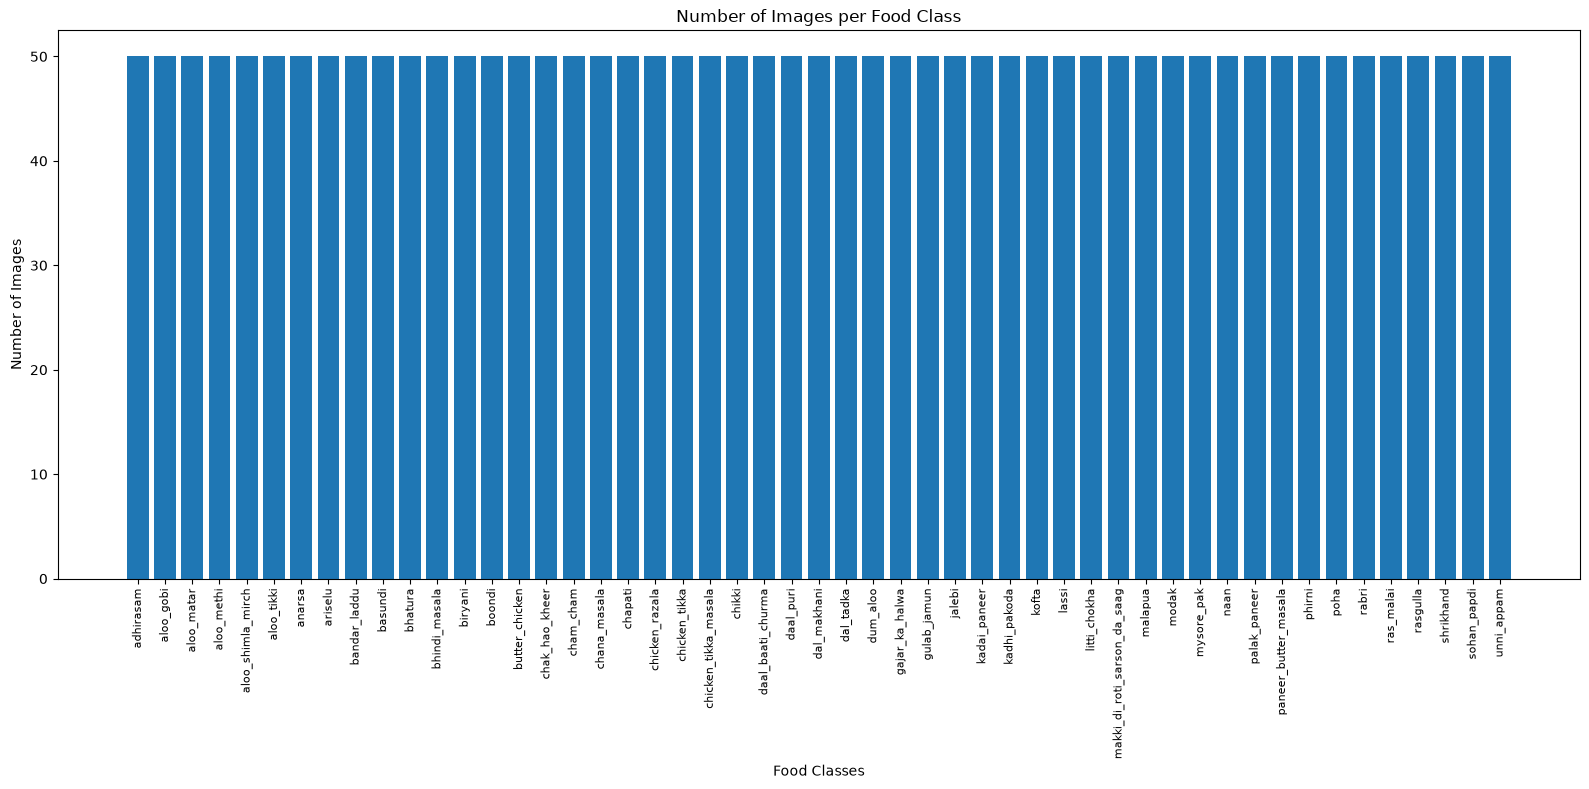

In [12]:
# ============================================================
# VISUALIZE IMAGE DISTRIBUTION
# ============================================================
plt.figure(figsize=(16, 8))
plt.bar(
    image_count_df["Food"],
    image_count_df["Number_of_Images"]
)
plt.xlabel("Food Classes")
plt.ylabel("Number of Images")
plt.title("Number of Images per Food Class")
plt.xticks(
    rotation=90,
    fontsize=8
)
plt.tight_layout()
plt.show()

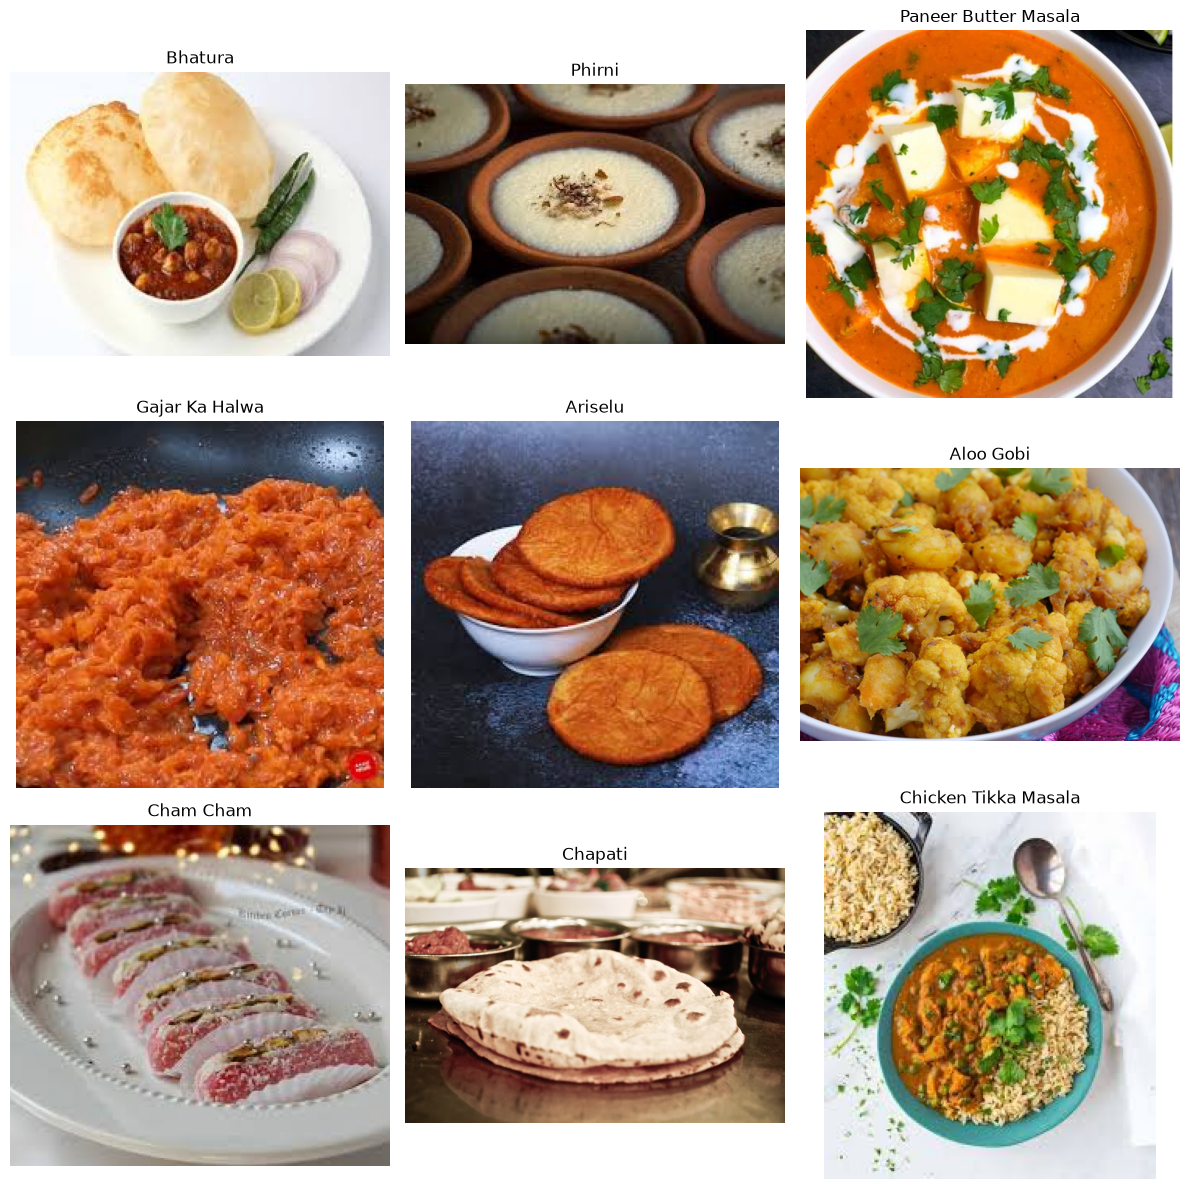

In [13]:
# ============================================================
# DISPLAY SAMPLE FOOD IMAGES
# ============================================================
import random
from PIL import Image
sample_foods = random.sample(matching_foods, 9)
plt.figure(figsize=(12, 12))
for i, food in enumerate(sample_foods):
    folder_path = os.path.join(TARGET_PATH, food)
    image_files = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith(image_extensions)
    ]
    image_file = random.choice(image_files)
    image_path = os.path.join(folder_path, image_file)
    img = Image.open(image_path)
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(food.replace("_", " ").title())
    plt.axis("off")
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# CREATE TRAINING AND VALIDATION DATA
# ============================================================
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.20
)
train_data = datagen.flow_from_directory(
    TARGET_PATH,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True
)
validation_data = datagen.flow_from_directory(
    TARGET_PATH,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)
print("\nTraining images:", train_data.samples)
print("Validation images:", validation_data.samples)
print("Number of classes:", train_data.num_classes)

Found 2040 images belonging to 51 classes.
Found 510 images belonging to 51 classes.

Training images: 2040
Validation images: 510
Number of classes: 51


In [15]:
# ============================================================
# CHECK CLASS NAMES
# ============================================================
class_names = list(train_data.class_indices.keys())
print("Number of classes:", len(class_names))
print("\nClass indices:")
for class_name, index in train_data.class_indices.items():
    print(f"{index:2} -> {class_name}")

Number of classes: 51

Class indices:
 0 -> adhirasam
 1 -> aloo_gobi
 2 -> aloo_matar
 3 -> aloo_methi
 4 -> aloo_shimla_mirch
 5 -> aloo_tikki
 6 -> anarsa
 7 -> ariselu
 8 -> bandar_laddu
 9 -> basundi
10 -> bhatura
11 -> bhindi_masala
12 -> biryani
13 -> boondi
14 -> butter_chicken
15 -> chak_hao_kheer
16 -> cham_cham
17 -> chana_masala
18 -> chapati
19 -> chicken_razala
20 -> chicken_tikka
21 -> chicken_tikka_masala
22 -> chikki
23 -> daal_baati_churma
24 -> daal_puri
25 -> dal_makhani
26 -> dal_tadka
27 -> dum_aloo
28 -> gajar_ka_halwa
29 -> gulab_jamun
30 -> jalebi
31 -> kadai_paneer
32 -> kadhi_pakoda
33 -> kofta
34 -> lassi
35 -> litti_chokha
36 -> makki_di_roti_sarson_da_saag
37 -> malapua
38 -> modak
39 -> mysore_pak
40 -> naan
41 -> palak_paneer
42 -> paneer_butter_masala
43 -> phirni
44 -> poha
45 -> rabri
46 -> ras_malai
47 -> rasgulla
48 -> shrikhand
49 -> sohan_papdi
50 -> unni_appam


In [16]:
# ============================================================
# LOAD PRETRAINED MOBILENETV2 MODEL
# ============================================================
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
# Freeze the pretrained layers
base_model.trainable = False
print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

MobileNetV2 loaded successfully!
Total layers: 154
Trainable: False


In [17]:
# ============================================================
# BUILD FOOD CLASSIFICATION MODEL
# ============================================================
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(
    128,
    activation="relu"
)(x)
output = Dense(
    51,
    activation="softmax"
)(x)
model = Model(
    inputs=base_model.input,
    outputs=output
)
print("Food classification model created successfully!")
print("\nModel output classes:", 51)

Food classification model created successfully!

Model output classes: 51


In [18]:
# ============================================================
# COMPILE THE MODEL
# ============================================================
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully!")

Model compiled successfully!


In [19]:
# ============================================================
# DISPLAY MODEL SUMMARY
# ============================================================

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,428,531 (9.26 MB)

 Trainable params: 170,547 (666.20 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# ============================================================
# TRAIN THE MODEL
# ============================================================
EPOCHS = 10
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1799 - loss: 3.2640

In [ ]:
# ============================================================
# PLOT TRAINING AND VALIDATION ACCURACY
# ============================================================
plt.figure(figsize=(10, 5))
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

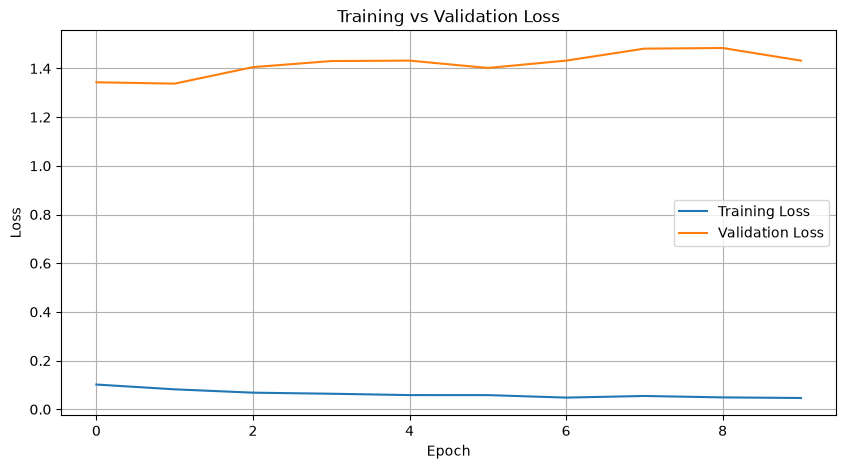

In [44]:
# ============================================================
# PLOT TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [45]:
# ============================================================
# EVALUATE THE MODEL
# ============================================================

validation_loss, validation_accuracy = model.evaluate(
    validation_data
)

print("\n========================================")
print("MODEL EVALUATION")
print("========================================")

print(f"Validation Loss     : {validation_loss:.4f}")
print(f"Validation Accuracy : {validation_accuracy:.4f}")
print(f"Validation Accuracy : {validation_accuracy * 100:.2f}%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 783ms/step - accuracy: 0.6314 - loss: 1.4321

MODEL EVALUATION
Validation Loss     : 1.4321
Validation Accuracy : 0.6314
Validation Accuracy : 63.14%


In [46]:
# ============================================================
# SAVE TRAINED MODEL
# ============================================================

MODEL_DIR = r"C:\Users\Megh\Food and Calories estimation\model"

os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "food_model.keras"
)

CLASS_NAMES_PATH = os.path.join(
    MODEL_DIR,
    "class_names.json"
)

# Save trained model
model.save(MODEL_PATH)

# Save class names
with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f, indent=4)

print("Model saved successfully!")
print("\nModel path:")
print(MODEL_PATH)

print("\nClass names saved successfully!")
print("\nClass names path:")
print(CLASS_NAMES_PATH)

Model saved successfully!

Model path:
C:\Users\Megh\Food and Calories estimation\model\food_model.keras

Class names saved successfully!

Class names path:
C:\Users\Megh\Food and Calories estimation\model\class_names.json


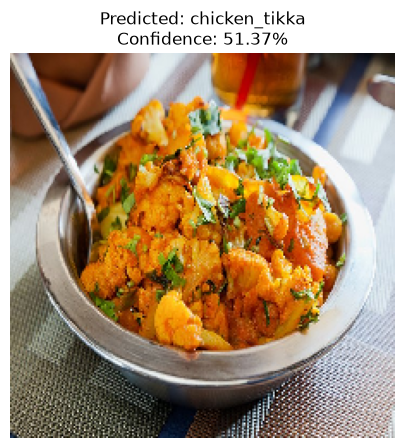

Actual food    : aloo_gobi
Predicted food : chicken_tikka
Confidence     : 51.37%


In [47]:
# ============================================================
#TEST FOOD IMAGE PREDICTION
# ============================================================

from tensorflow.keras.preprocessing import image

# Select one image from the dataset
test_food = "aloo_gobi"

test_folder = os.path.join(
    TARGET_PATH,
    test_food
)

test_image_file = [
    file
    for file in os.listdir(test_folder)
    if file.lower().endswith(image_extensions)
][0]

test_image_path = os.path.join(
    test_folder,
    test_image_file
)

# Load and preprocess image
img = image.load_img(
    test_image_path,
    target_size=IMAGE_SIZE
)

img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array, verbose=0)

predicted_index = np.argmax(prediction[0])
predicted_food = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(
    f"Predicted: {predicted_food}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print("Actual food    :", test_food)
print("Predicted food :", predicted_food)
print(f"Confidence     : {confidence:.2f}%")

In [49]:
# ============================================================
# CELL 21: TEST MULTIPLE FOOD CLASSES
# ============================================================

test_foods = [
    "biryani",
    "gulab_jamun",
    "palak_paneer",
    "poha"
]

print("========================================")
print("MULTIPLE IMAGE PREDICTION TEST")
print("========================================")

for actual_food in test_foods:

    test_folder = os.path.join(
        TARGET_PATH,
        actual_food
    )

    image_files = [
        file
        for file in os.listdir(test_folder)
        if file.lower().endswith(image_extensions)
    ]

    test_image_file = image_files[0]

    test_image_path = os.path.join(
        test_folder,
        test_image_file
    )

    # Load image
    img = image.load_img(
        test_image_path,
        target_size=IMAGE_SIZE
    )

    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = model.predict(
        img_array,
        verbose=0
    )

    predicted_index = np.argmax(prediction[0])
    predicted_food = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    print(f"\nActual     : {actual_food}")
    print(f"Predicted  : {predicted_food}")
    print(f"Confidence : {confidence:.2f}%")

MULTIPLE IMAGE PREDICTION TEST

Actual     : biryani
Predicted  : biryani
Confidence : 92.59%

Actual     : gulab_jamun
Predicted  : gulab_jamun
Confidence : 98.85%

Actual     : palak_paneer
Predicted  : palak_paneer
Confidence : 42.51%

Actual     : poha
Predicted  : poha
Confidence : 96.02%
